# Lesson 11 · Simulation: does empirical Bayes actually work?

**Source:** *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 12 (pp. 115–129)

**Question:** We never get to see a player's true batting average, so how do we know shrinkage helps? Build a world where we *do* know the truth, and check.

**Goal:** Simulate batting records from a known prior, then measure how well shrinkage, credible intervals, q-values and beta-binomial regression recover the truth.

**Contents**

1. The generative model
2. Simulate one world
3. Shrinkage: accuracy and bias
4. Credible intervals: are they calibrated?
5. FDR control: does q < 0.1 mean 10%?
6. Beta-binomial regression: parameter recovery
7. Exercises

**Tags:** `simulation` `bias-variance` `mean-squared-error` `calibration` `coverage` `fdr-control` `parameter-recovery`

**Before you start:** Lesson 10 (`my_eb.py`). If you skipped it, use your functions from Lessons 02–06 instead.

*How this notebook works:* each **Your turn** prompt is followed by an empty cell for your code. **Check** boxes give values to compare against; they come from the book, and your numbers can differ slightly because the Lahman data now runs through more recent seasons. **Reflect** prompts are for short written answers. Every prompt is numbered *lesson.section.question* (for example **2.3.1**), so you can refer to it; empty code cells and answer cells carry the same number.

In [1]:
# --- Setup: run this cell first ------------------------------------------
# Windows + conda: put the environment's DLL folders on PATH, so plotting
# can't crash the kernel when Jupyter wasn't started from the activated env.
import os, sys
for sub in ["Library\\mingw-w64\\bin", "Library\\usr\\bin", "Library\\bin", "Scripts", "bin"]:
    p = os.path.join(sys.prefix, sub)
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, optimize, special

import eb_data   # helpers in this folder: loading the Lahman data, saving results

rng = np.random.default_rng(2017)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (7, 4)
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

%load_ext autoreload
%autoreload 2
try:
    import my_eb   # your toolkit from Lesson 10
except ImportError:
    print("my_eb.py not found: finish Lesson 10, or define the functions you need below.")

career = eb_data.career(pitcher_rule=3)[["playerID", "H", "AB"]]
print(f"{len(career):,} players")

numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1
my_eb.py not found: finish Lesson 10, or define the functions you need below.
13,446 players


## 1. The generative model

$$p_i \sim \text{Beta}(\alpha_0, \beta_0), \qquad H_i \sim \text{Binomial}(AB_i, p_i).$$

- $\alpha_0, \beta_0$: estimate them from the real data, so the simulated world looks realistic.
- $p_i$: simulate. These are the true averages we normally never see.
- $AB_i$: reuse the real values. We aren't trying to estimate them.

**11.1.1 · Your turn.** Fit the prior to **all** players this time (no AB filter). Plot the distribution of AB (log x) to see why we reuse it rather than simulate it.

66.67350186171704 200.2543620457619


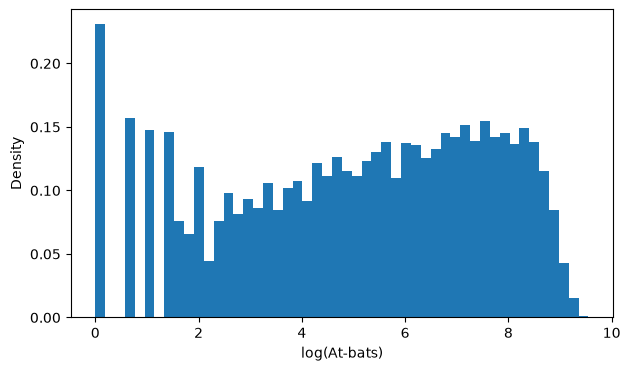

In [2]:
# 11.1.1 · Your code here

#make a second copy of career for 11.6
career2 = career.copy()

def neg_log_lik(params, H, AB):
    log_a, log_b = params       
    a, b = np.exp(log_a), np.exp(log_b)
    bbsum = stats.betabinom.logpmf(H, AB, a, b).sum()
    return -bbsum             

res = optimize.minimize(neg_log_lik, x0=np.log([1, 10]), args=(career.H, career.AB), method="Nelder-Mead")
a_all, b_all = np.exp(res.x)
print(a_all, b_all)

plt.hist(np.log(career.AB), bins = 50, density = True)
plt.xlabel("log(At-bats)")
plt.ylabel("Density")
plt.show()

> **Check:** the book got α₀ ≈ 72.1, β₀ ≈ 215.1.

## 2. Simulate one world

**11.2.1 · Your turn.** With a fixed seed, add a true `p` (beta draws) and a simulated `H` (binomial draws using the real AB) to a copy of `career`. Then run your empirical Bayes estimation on the simulated data.

In [3]:
# 11.2.1 · Your code here
career['sim_p'] = rng.beta(a_all, b_all, size = len(career))
career['sim_H'] = rng.binomial(career.AB, career.sim_p)
career['sim_a1'] = a_all + career.sim_H
career['sim_b1'] = b_all + career.AB - career.sim_H
career['sim_EBest'] = (career.sim_a1 / (career.sim_a1 + career.sim_b1))
career.head()

,playerID,H,AB,sim_p,sim_H,sim_a1,sim_b1,sim_EBest
0,aaronha01,3771,12364,0.2651,3295,3361.6735,9269.2544,0.2661
1,aaronto01,216,944,0.2175,185,251.6735,959.2544,0.2078
2,abadan01,2,21,0.2994,6,72.6735,215.2544,0.2524
3,abadijo01,11,49,0.2865,13,79.6735,236.2544,0.2522
4,abbated01,772,3044,0.2738,816,882.6735,2428.2544,0.2666


## 3. Shrinkage: accuracy and bias

**11.3.1 · Your turn.** Two panels: raw estimate vs true p, and shrunken estimate vs true p (AB ≥ 10, colored by AB). Add the y = x line and a fitted regression line to each.

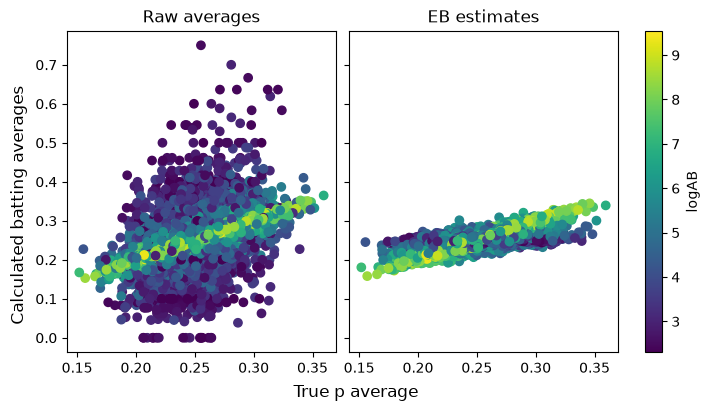

In [4]:
# 11.3.1 · Your code here

fig, ax = plt.subplots(1, 2, sharey = True, layout = "constrained")
career10 = career[career.AB >= 10]
sc = ax[0].scatter(career10.sim_p, (career10.sim_H/career10.AB), c = np.log(career10.AB))
ax[0].set_title("Raw averages")
ax[1].scatter(career10.sim_p, career10.sim_EBest, c = np.log(career10.AB))
ax[1].set_title("EB estimates")
fig.supxlabel("True p average")
fig.supylabel("Calculated batting averages")
fig.colorbar(sc, ax = ax, label = "logAB")
plt.show()

**11.3.2 · Your turn.** Compute the overall mean squared error of raw and shrunken estimates.

In [5]:
# 11.3.2 · Your code here
def mse(estimate, actual):
    return np.mean((estimate - actual) ** 2)
        
MSE_raw = mse((career.sim_H / career.AB), career.sim_p)
MSE_eb = mse(career.sim_EBest, career.sim_p)

print(f"Raw MSE: {MSE_raw} vs EB MSE: {MSE_eb}")

Raw MSE: 0.01682382568923358 vs EB MSE: 0.00038025142449809636


> **Check:** raw MSE ≈ 0.015; shrunken ≈ 0.00035.

**11.3.3 · Your turn.** Bin players by AB (`10 ** np.round(np.log10(AB))`). Within each bin compute the MSE and the *slope* of estimate on true p (a slope below 1 means bias toward the middle). Plot both against AB, for raw and shrunken.

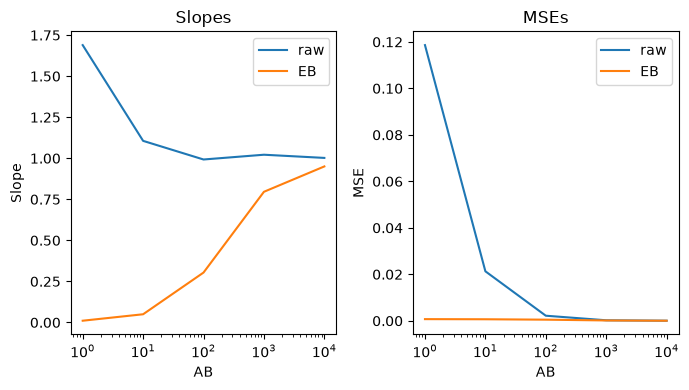

In [6]:
# 11.3.3 · Your code here
career['AB_bin'] = 10 ** np.round(np.log10(career.AB))

def bin_slope(df):
    mse_raw = mse(df.sim_H / df.AB, df.sim_p)
    mse_eb = mse(df.sim_EBest, df.sim_p)
    slope_raw = np.polyfit(df.sim_p, df.sim_H / df.AB, 1)[0]
    slope_eb = np.polyfit(df.sim_p, df.sim_EBest, 1)[0]
    return pd.Series({'mse_raw' : mse_raw, 'mse_eb': mse_eb, 'slope_raw': slope_raw, 'slope_eb': slope_eb})

binned = career.groupby('AB_bin', as_index = False).apply(bin_slope)
fig, ax = plt.subplots(1, 2)

for i, group in enumerate(zip([binned.slope_raw, binned.mse_raw], [binned.slope_eb, binned.mse_eb], ['Slope', 'MSE'])):
    ax[i].plot(binned.AB_bin, group[0], label ='raw')
    ax[i].plot(binned.AB_bin, group[1], label = 'EB')
    ax[i].set_xscale("log")
    ax[i].set_xlabel("AB")
    ax[i].set_ylabel(group[2])
    ax[i].set_title(group[2] + 's')
    ax[i].legend()
plt.tight_layout()
plt.show()

**11.3.4 · Reflect.** Shrinkage adds bias and removes variance. Where is that trade most worthwhile, and where does it hardly matter?

*11.3.4 · Your answer:*

## 4. Credible intervals: are they calibrated?

**11.4.1 · Your turn.** What fraction of 95% credible intervals contain the true p? Then plot 20 random players' intervals with the true p as a red dot.

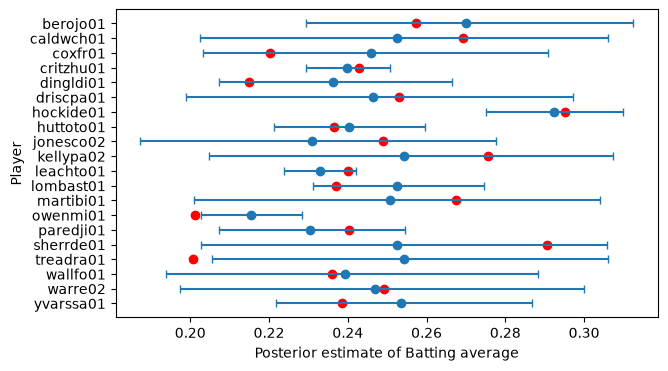

In [7]:
# 11.4.1 · Your code here

rand20 = rng.integers(0, len(career), size = 20)
rand20.sort()

career['low'] = stats.beta(career.sim_a1, career.sim_b1).ppf(0.025)
career['high'] = stats.beta(career.sim_a1, career.sim_b1).ppf(0.975)
career['in95CI'] = career['sim_p'].between(career.low, career.high)
career['in95CI'].sum() / len(career)


y = np.arange(len(rand20), 0, -1)

xerr = [career.iloc[rand20].sim_EBest - career.iloc[rand20].low,     
        career.iloc[rand20].high - career.iloc[rand20].sim_EBest]  

plt.errorbar(career.iloc[rand20].sim_EBest, y, xerr = xerr, fmt="o", capsize=3)
plt.scatter(career.iloc[rand20].sim_p, y, color = 'red')
plt.yticks(y, career.iloc[rand20].playerID.tolist())
plt.xlabel('Posterior estimate of Batting average')
plt.ylabel('Player')
plt.show()    
        

> **Check:** coverage ≈ 0.95.

**11.4.2 · Your turn.** Repeat for credible levels from 0.50 to 0.98 and plot coverage against level, with the line y = x. Print progress as you loop.

Level 0.50 completed
Level 0.60 completed
Level 0.70 completed
Level 0.80 completed
Level 0.90 completed


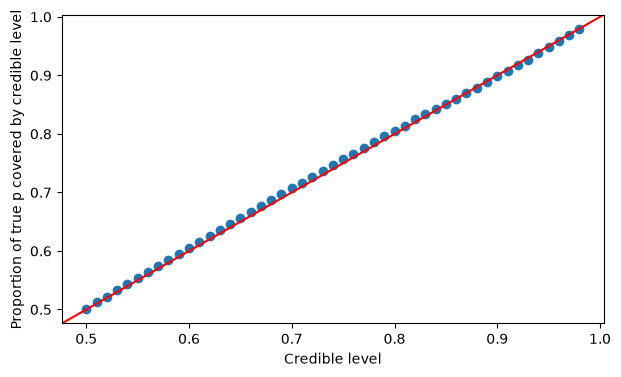

In [8]:
# 11.4.2 · Your code here

props = []
levels = np.arange(0.5, 0.99, 0.01)

def inlevel(level, df):
    lower = stats.beta(df.sim_a1, df.sim_b1).ppf((1 - level)/2)
    upper =  stats.beta(df.sim_a1, df.sim_b1).ppf(1 - (1 - level)/2)
    return df.sim_p.between(lower, upper).mean()

for i, level in enumerate(levels):
    prop = inlevel(level, career)
    props.append(prop)
    if (i % 10) == 0:
        print(f"Level {level:.2f} completed")
    
plt.scatter(levels, props)
plt.axline((0.5, 0.5), slope=1, color = 'red')
plt.xlabel('Credible level')
plt.ylabel('Proportion of true p covered by credible level')
plt.show()    
        

## 5. FDR control: does q < 0.1 mean 10%?

**11.5.1 · Your turn.** Run your proportion test against .300 on the simulated data. Admit players with q ≤ 0.1. What fraction of them truly have p < .300?

In [9]:
# 11.5.1 · Your code here
career['PEP0.3'] = stats.beta(career.sim_a1, career.sim_b1).cdf(0.3)
career = career.sort_values('PEP0.3')
career['Rank'] = range(1, len(career) + 1)
career['qval'] = np.cumsum(career['PEP0.3'] / career.Rank)
print(f"# of players with 0.3 batting average or better with 10% FDR: {len(career[career.qval <= 0.1])}")
print(f"Fraction with 'true' p < 0.3 : {len(career[(career.qval <= 0.1) & (career.sim_p < 0.3)])/len(career[career.qval <= 0.1])}")

# of players with 0.3 batting average or better with 10% FDR: 79
Fraction with 'true' p < 0.3 : 0.08860759493670886


> **Check:** about 0.09–0.10.

**11.5.2 · Your turn.** For every q-value threshold, plot the *true* false discovery proportion (cumulative mean of `p < 0.3`, sorted by q) against the threshold.

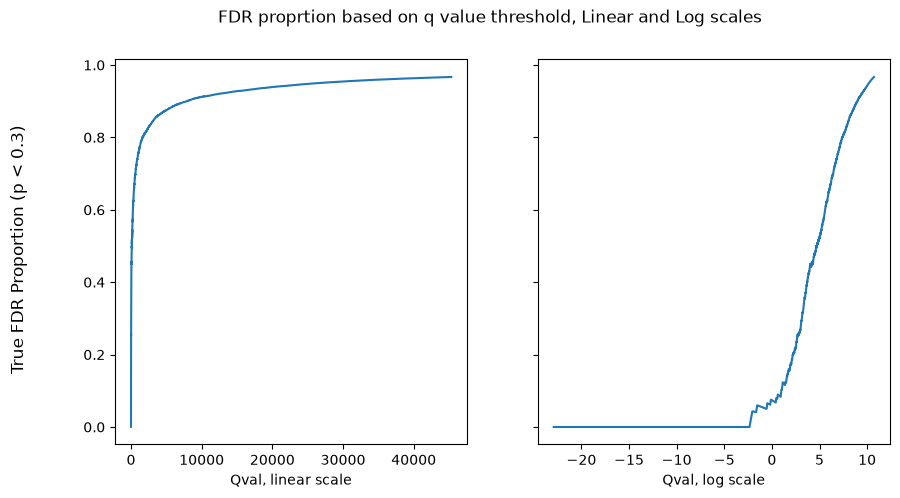

In [10]:
# 11.5.2 · Your code here
career.head()

fig, axes = plt.subplots(1, 2, figsize = (10, 5), sharey = True)
axes[0].plot(np.cumsum(career.qval), np.cumsum(career.sim_p < 0.3) / career.Rank)
axes[0].set_xlabel("Qval, linear scale")
axes[1].plot(np.log(np.cumsum(career.qval)), np.cumsum(career.sim_p < 0.3) / career.Rank)
axes[1].set_xlabel("Qval, log scale")
fig.supylabel("True FDR Proportion (p < 0.3)")
fig.suptitle("FDR proprtion based on q value threshold, Linear and Log scales")
plt.show()



## 6. Beta-binomial regression: parameter recovery

Now make the world more realistic: let the prior mean depend on log10(AB), as in Lesson 06. Note that `ebbr` uses a **logit** link here, so its coefficients aren't on the same scale as Lesson 06's.

**11.6.1 · Your turn.** Fit the regression prior to the real data. Use the fitted coefficients as the *true* hyperparameters: simulate p from each player's own prior, then H.

In [11]:
# 11.6.1 · Your code here
Xlogit2 = np.column_stack((np.full(len(career), 1), np.log10(career2.AB)))

def bb_reg_neg_logit_lik(params, H, AB, X):
    [*b, log_sigma] = params
    mu = special.expit(X @ b)
    sigma = np.exp(log_sigma)
    alpha = mu / sigma
    beta = ((1 - mu)/sigma)
    return -stats.betabinom.logpmf(H, AB, alpha, beta).sum()

def fit_bb_regression_logit(H, AB, X, start = None):
    if start is None:
        start = [special.logit(0.2), 0.01, -6]
    res = optimize.minimize(bb_reg_neg_logit_lik, x0 = start, args = (H, AB, X), method = "L-BFGS-B")
    coeffs = res.x[:-1]
    sigfit = res.x[-1]
    return *coeffs, np.exp(sigfit)

mu0_logit, muAB_logit, sig_logit = fit_bb_regression_logit(career2.H, career2.AB, Xlogit2)
logitfits = np.array([mu0_logit, muAB_logit, sig_logit])

In [12]:
print(mu0_logit, muAB_logit, sig_logit)

-1.6556712869224224 0.18242209404113735 0.0021760672602952856


In [13]:
def to_alpha_beta(mu, sigma):
    alpha = mu / sigma
    beta = ((1 - mu) / sigma)
    return alpha, beta

career2['mu_player'] = special.expit(mu0_logit + (muAB_logit * np.log10(career2.AB)))
career2['a_sim'], career2['b_sim'] = to_alpha_beta(career2['mu_player'], sig_logit)
career2['sim_p'] = rng.beta(career2.a_sim, career2.b_sim, size = len(career2))
career2['sim_H'] = rng.binomial(career2.AB, career2.sim_p)
career2.head()

,playerID,H,AB,mu_player,a_sim,b_sim,sim_p,sim_H
0,aaronha01,3771,12364,0.2872,131.9672,327.5774,0.2542,3163
1,aaronto01,216,944,0.2473,113.6534,345.8912,0.2398,235
2,abadan01,2,21,0.1955,89.8548,369.6898,0.2103,2
3,abadijo01,11,49,0.2063,94.8065,364.7382,0.2308,7
4,abbated01,772,3044,0.2650,121.7728,337.7719,0.2940,897


> **Check:** with a logit link the book got μ intercept ≈ −1.688, log10(AB) slope ≈ 0.192, log σ ≈ −6.30.

**11.6.2 · Your turn.** Refit the regression on the simulated data. Do you recover the true coefficients (compare with their standard errors)?

In [14]:
# 11.6.2 · Your code here
mu0_logit_sim, muAB_logit_sim, sig_logit_sim = fit_bb_regression_logit(career2.sim_H, career2.AB, Xlogit2)
logitfits_sim = np.array([mu0_logit_sim, muAB_logit_sim, sig_logit_sim])
print(logitfits_sim)

errors = []
for f, g in zip(logitfits, logitfits_sim):
    errors.append((g-f) ** 2)

[-1.66005589  0.18415427  0.00213566]


In [18]:
print("", "Intercept", "Slope", "Sigma", sep="\t")
print('True:\t', "\t".join(f"{x:.4f}" for x in logitfits))
print('Sim:\t', "\t".join(f"{x:.4f}" for x in logitfits_sim))
print('Error: \t')


	Intercept	Slope	Sigma
True:	 -1.6557	0.1824	0.0022
Sim:	 -1.6601	0.1842	0.0021
Error: 	


**11.6.3 · Your turn.** Compare shrunken estimates against true p using (a) a single flat prior and (b) the AB-dependent prior.

In [22]:
# 11.6.3 · Your code here
career2['a1_sim'] = career2.a_sim + career2.sim_H
career2['b1_sim'] = career2.b_sim + career2.AB - career2.sim_H
career2['EBest_sim'] = (career2.a1_sim / (career2.a1_sim + career2.b1_sim))

,playerID,H,AB,mu_player,a_sim,b_sim,sim_p,sim_H,a1_sim,b1_sim,EBest_sim
0,aaronha01,3771,12364,0.2872,131.9672,327.5774,0.2542,3163,3294.9672,9528.5774,0.2569
1,aaronto01,216,944,0.2473,113.6534,345.8912,0.2398,235,348.6534,1054.8912,0.2484
2,abadan01,2,21,0.1955,89.8548,369.6898,0.2103,2,91.8548,388.6898,0.1911
3,abadijo01,11,49,0.2063,94.8065,364.7382,0.2308,7,101.8065,406.7382,0.2002
4,abbated01,772,3044,0.2650,121.7728,337.7719,0.2940,897,1018.7728,2484.7719,0.2908


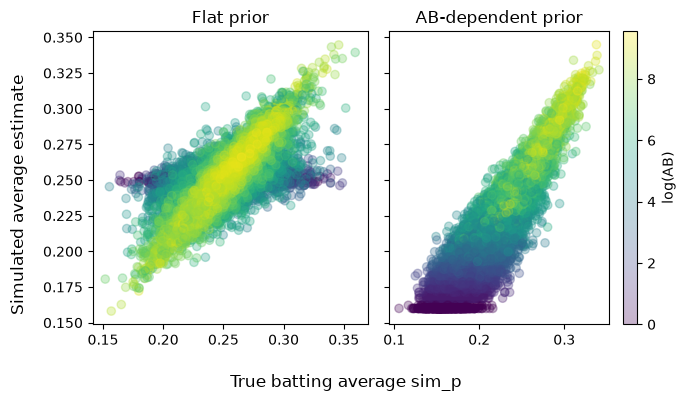

In [32]:
fig, ax = plt.subplots(1, 2, sharey = True)
sc = ax[0].scatter(career.sim_p, career.sim_EBest, alpha = 0.3, c = np.log(career.AB))
ax[0].set_title("Flat prior")

ax[1].scatter(career2.sim_p, career2.EBest_sim, alpha = 0.3, c = np.log(career2.AB))
ax[1].set_title("AB-dependent prior")

fig.supxlabel("True batting average sim_p")
fig.supylabel("Simulated average estimate")
cbar = fig.colorbar(sc, ax=ax[1], orientation="vertical")
cbar.set_label("log(AB)")
plt.tight_layout()
plt.show()

**11.6.4 · Reflect.** **Card connection.** A *parameter-recovery check* simulates data from known parameters, fits the model, and asks whether the fit gets them back. Notebook 07b of Cardprice (a separate project, not included in this repository, that models trading-card sale prices) has a `USE_SIMULATED` switch for exactly this. If you have that project: what did the check tell you about its model, and what's one check from this lesson you could add there? If not, answer for any model you've fitted to real data.

*11.6.4 · Your answer:*

## 7. Exercises

**11.7.1 · Your turn.** Fit the prior by the method of moments instead of MLE and repeat the MSE and coverage checks. Is it noticeably worse?

In [17]:
# 11.7.1 · Your code here

## References

- *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 12.
- Morris, White & Crowther (2019), "Using simulation studies to evaluate statistical methods", *Statistics in Medicine* 38(11).
- Talts et al. (2018), "Validating Bayesian inference algorithms with simulation-based calibration", arXiv:1804.06788.